In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("hotel_bookings.csv")
df
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.tail()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


In [4]:
df.shape


(119390, 32)

In [5]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
df.isnull().sum()

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [8]:
df['children'] = df['children'].fillna(0)

df['country'] = df['country'].fillna('Unknown')

df['agent'] = df['agent'].fillna(0)

df['company'] = df['company'].fillna(0)

In [9]:
df.isnull().sum()

hotel                             0
is_canceled                       0
lead_time                         0
arrival_date_year                 0
arrival_date_month                0
arrival_date_week_number          0
arrival_date_day_of_month         0
stays_in_weekend_nights           0
stays_in_week_nights              0
adults                            0
children                          0
babies                            0
meal                              0
country                           0
market_segment                    0
distribution_channel              0
is_repeated_guest                 0
previous_cancellations            0
previous_bookings_not_canceled    0
reserved_room_type                0
assigned_room_type                0
booking_changes                   0
deposit_type                      0
agent                             0
company                           0
days_in_waiting_list              0
customer_type                     0
adr                         

In [10]:
df.duplicated().sum()

np.int64(31994)

In [11]:
df = df.drop_duplicates()

In [12]:
print("Final dataset shape:", df.shape)

Final dataset shape: (87396, 32)


In [13]:
import pandas as pd
df=pd.read_csv("hotel_bookings.csv")

In [14]:
df.replace('Undefined', 'Unknown', inplace=True)

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.00,0,1,Check-Out,2015-07-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07


In [15]:
df[df['adr'] < 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
14969,Resort Hotel,0,195,2017,March,10,5,4,6,2,...,No Deposit,273.0,NaN,0,Transient-Party,-6.38,0,0,Check-Out,2017-03-15


In [16]:
df[(df['adults'] + df['children'] + df['babies']) == 0]

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
2224,Resort Hotel,0,1,2015,October,41,6,0,3,0,...,No Deposit,NaN,174.0,0,Transient-Party,0.00,0,0,Check-Out,2015-10-06
2409,Resort Hotel,0,0,2015,October,42,12,0,0,0,...,No Deposit,NaN,174.0,0,Transient,0.00,0,0,Check-Out,2015-10-12
3181,Resort Hotel,0,36,2015,November,47,20,1,2,0,...,No Deposit,38.0,NaN,0,Transient-Party,0.00,0,0,Check-Out,2015-11-23
3684,Resort Hotel,0,165,2015,December,53,30,1,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,2016-01-04
3708,Resort Hotel,0,165,2015,December,53,30,2,4,0,...,No Deposit,308.0,NaN,122,Transient-Party,0.00,0,0,Check-Out,2016-01-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115029,City Hotel,0,107,2017,June,26,27,0,3,0,...,No Deposit,7.0,NaN,0,Transient,100.80,0,0,Check-Out,2017-06-30
115091,City Hotel,0,1,2017,June,26,30,0,1,0,...,No Deposit,NaN,NaN,0,Transient,0.00,1,1,Check-Out,2017-07-01
116251,City Hotel,0,44,2017,July,28,15,1,1,0,...,No Deposit,425.0,NaN,0,Transient,73.80,0,0,Check-Out,2017-07-17
116534,City Hotel,0,2,2017,July,28,15,2,5,0,...,No Deposit,9.0,NaN,0,Transient-Party,22.86,0,1,Check-Out,2017-07-22


In [17]:
df['total_guests'] = (
    df['adults'] + df['children'] + df['babies']
)

In [18]:
df[['adults','children','babies','total_guests']].head()


,adults,children,babies,total_guests
0,2,0.0,0,2.0
1,2,0.0,0,2.0
2,1,0.0,0,1.0
3,1,0.0,0,1.0
4,2,0.0,0,2.0


In [ ]:
print(df.isnull().sum())


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

In [ ]:
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

In [21]:
df=pd.read_csv("hotel_bookings.csv")

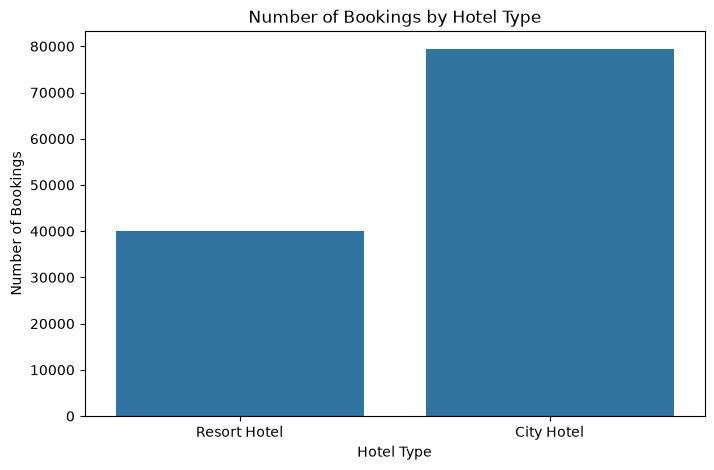

In [22]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='hotel')

plt.title('Number of Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.show()

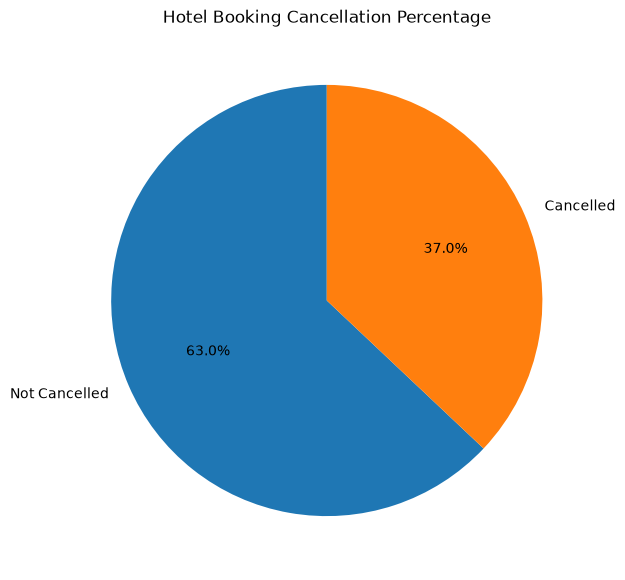

In [23]:
cancellation = df['is_canceled'].value_counts()

plt.figure(figsize=(7,7))

plt.pie(cancellation,
        labels=['Not Cancelled', 'Cancelled'],
        autopct='%1.1f%%',
        startangle=90)

plt.title('Hotel Booking Cancellation Percentage')

plt.show()

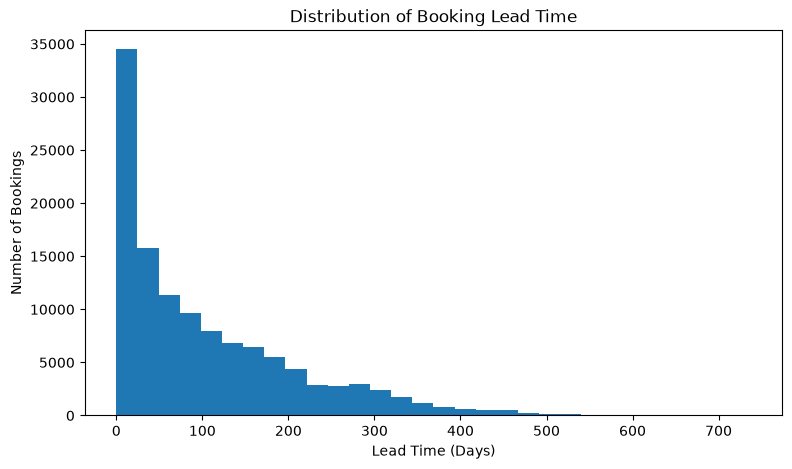

In [24]:
plt.figure(figsize=(9,5))

plt.hist(df['lead_time'], bins=30)

plt.title('Distribution of Booking Lead Time')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Bookings')

plt.show()

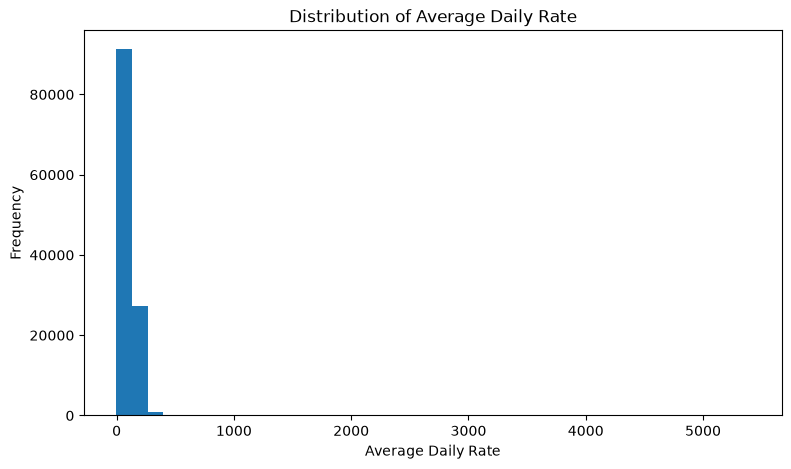

In [25]:
plt.figure(figsize=(9,5))

plt.hist(df['adr'], bins=40)

plt.title('Distribution of Average Daily Rate')
plt.xlabel('Average Daily Rate')
plt.ylabel('Frequency')

plt.show()

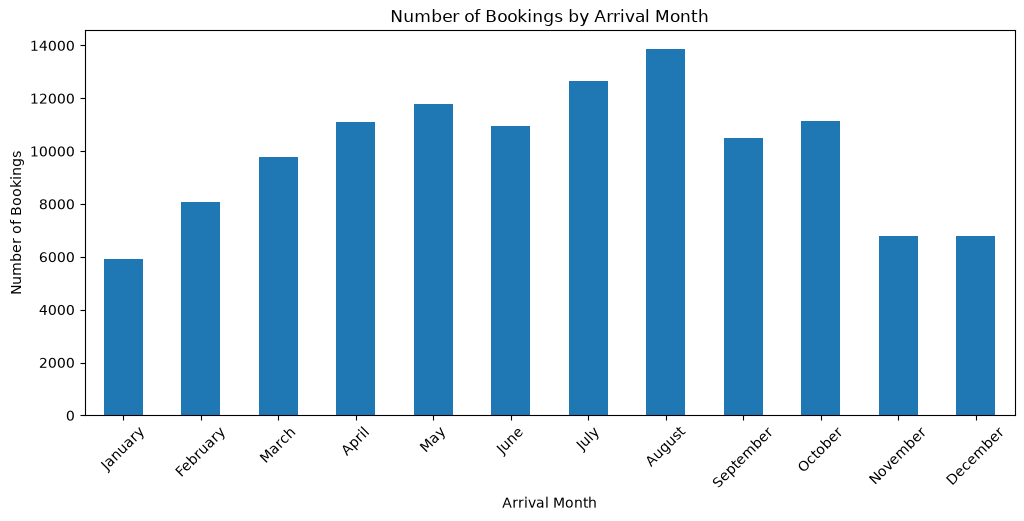

In [26]:
monthly_bookings = df['arrival_date_month'].value_counts()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = monthly_bookings.reindex(month_order)

plt.figure(figsize=(12,5))

monthly_bookings.plot(kind='bar')

plt.title('Number of Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()

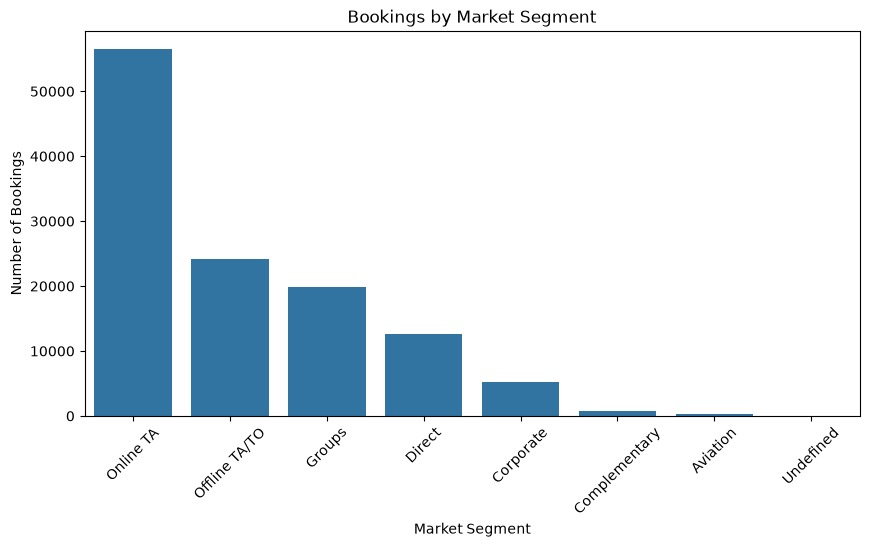

In [27]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='market_segment',
              order=df['market_segment'].value_counts().index)

plt.title('Bookings by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()

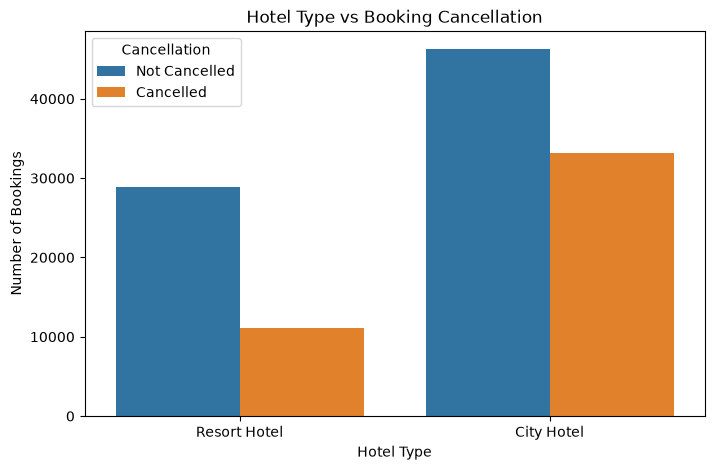

In [28]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x='hotel', hue='is_canceled')

plt.title('Hotel Type vs Booking Cancellation')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')

plt.legend(title='Cancellation',
           labels=['Not Cancelled', 'Cancelled'])

plt.show()

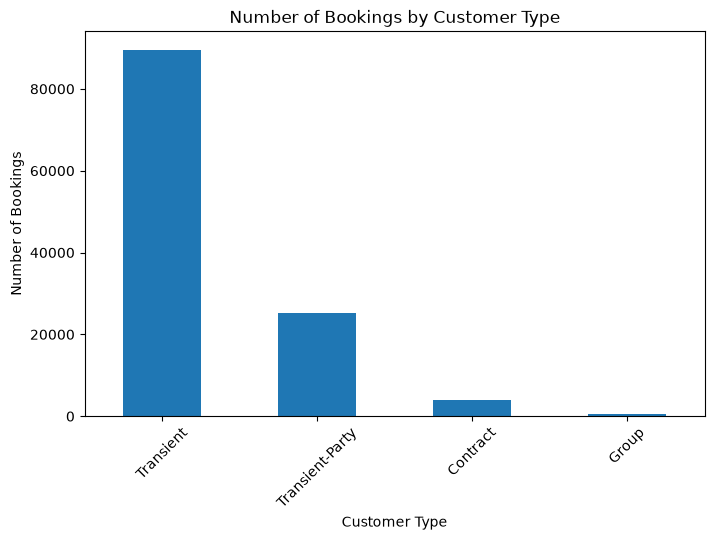

In [29]:
customer_count = df['customer_type'].value_counts()

plt.figure(figsize=(8,5))

customer_count.plot(kind='bar')

plt.title('Number of Bookings by Customer Type')
plt.xlabel('Customer Type')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)

plt.show()


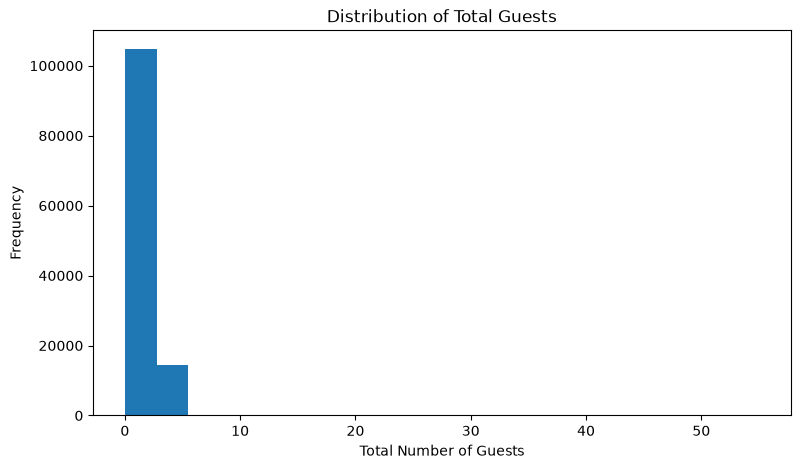

In [30]:
df['total_guests'] = (
    df['adults'] + df['children'] + df['babies']
)

plt.figure(figsize=(9,5))

plt.hist(df['total_guests'], bins=20)

plt.title('Distribution of Total Guests')
plt.xlabel('Total Number of Guests')
plt.ylabel('Frequency')

plt.show()


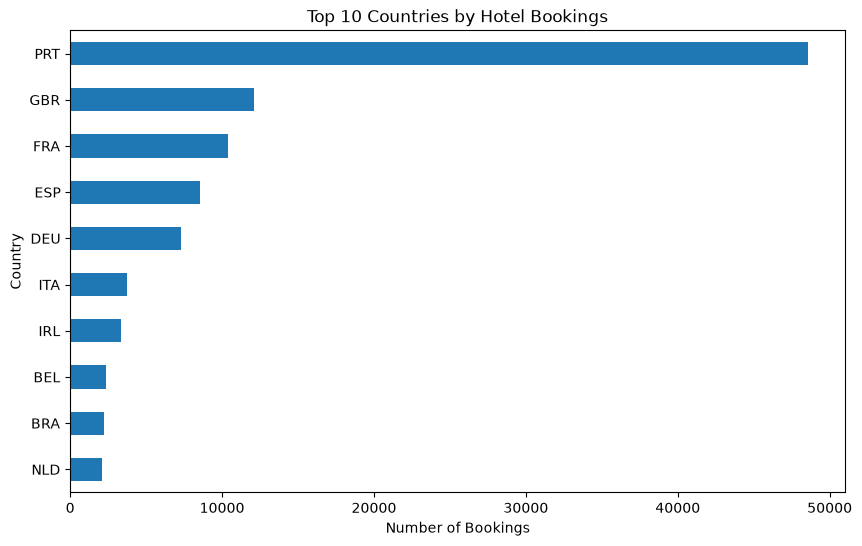

In [32]:
top_countries = df['country'].value_counts().head(10)

plt.figure(figsize=(10,6))

top_countries.plot(kind='barh')

plt.title('Top 10 Countries by Hotel Bookings')
plt.xlabel('Number of Bookings')
plt.ylabel('Country')

plt.gca().invert_yaxis()

plt.show()

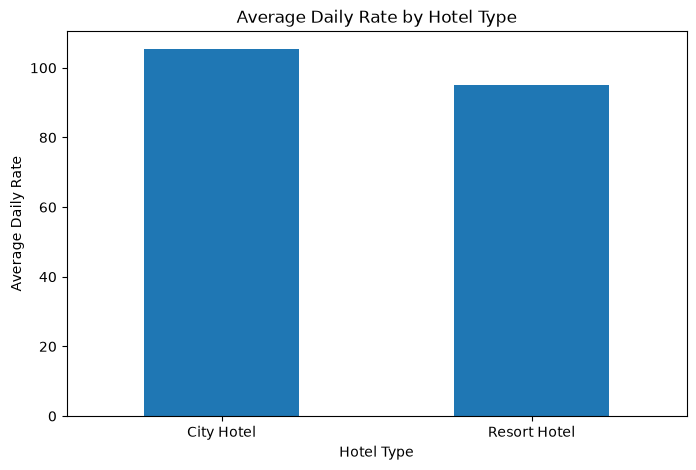

In [33]:
average_adr = df.groupby('hotel')['adr'].mean()

plt.figure(figsize=(8,5))

average_adr.plot(kind='bar')

plt.title('Average Daily Rate by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate')

plt.xticks(rotation=0)

plt.show()

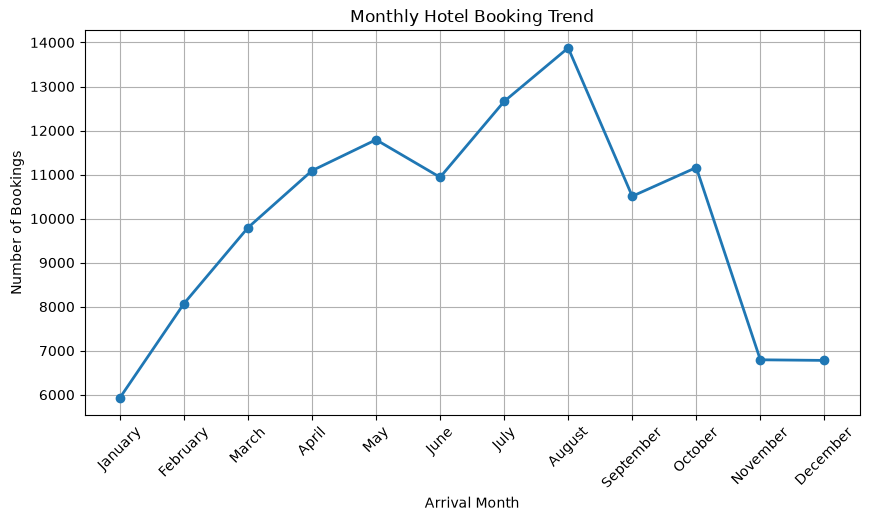

In [35]:
monthly_bookings = df['arrival_date_month'].value_counts()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_bookings = monthly_bookings.reindex(month_order)

plt.figure(figsize=(10,5))

plt.plot(month_order, monthly_bookings, marker='o',
         linestyle='-', linewidth=2)

plt.title('Monthly Hotel Booking Trend')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')

plt.xticks(rotation=45)
plt.grid(True)

plt.show()

In [ ]:
                                     PROJECT REPORT 
1.INTRODUCTION 
This project analyses a hotel-booking dataset using Python in a Jupyter Notebook. The work 
includes loading and inspecting the data, identifying missing and duplicate records, handling 
selected missing values, checking unusual records, creating a total-guest feature, and preparing 
visualizations to explore booking patterns. The original dataset contains 119,390 records and 
32 columns. The notebook reports 31,994 duplicate rows and a dataset size of 87,396 rows 
after duplicate removal. Visualizations examine hotel type, cancellations, booking lead time, 
average daily rate, arrival month, market segment, customer type, guest counts, country of 
origin and average daily rate by hotel type 

2. OBJECTIVES 
• To load the hotel-booking dataset into a Pandas Data Frame. 
• To inspect the structure, dimensions, column names and data types.  
• To identify missing values and duplicate records. 
• To handle missing values in selected columns and remove duplicate rows.  
• To inspect unusual values and create a total-guests column.  
• To visualize booking patterns and compare selected booking characteristics. 

3.TOOLS AND TECHNOLOGIES USED 
Python: Programming language used for data analysis.  
Jupyter Notebook: Interactive environment for writing and executing code.  
Pandas: Loading, inspecting, cleaning and grouping tabular data.  
NumPy: Numerical computing support.  
Matplotlib: Plotting charts and graphs.  
Seaborn: Statistical visualization, including count plots. 

4. DATASET DESCRIPTION  
The notebook loads the file named hotel_bookings.csv. The initial dataset has 119,390 rows 
and 32 columns. The columns include hotel type, cancellation status, lead time, arrival date, 
length of stay, number of adults/children/babies, meal, country, market segment, distribution 
channel, repeat-guest information, room types, deposit type, customer type, average daily rate 
(ADR), special requests, reservation status and reservation-status date. 
• Initial number of rows - 119,390 
• Number of columns     - 32 
• Duplicate rows identified  - 31,994 
• Rows after duplicate removal  -  87,396 

5. METHODOLOGY  
• Loading and initial inspection  
The notebook imports Pandas, NumPy, Matplotlib and Seaborn, then reads the CSV 
file with pd.read_csv(). The first and last records are viewed using head() and tail(). 
The shape, columns and info() methods are used to understand the dataset dimensions, 
variables and data types. 
    
• Missing-value identification and treatment  
Missing values are checked using null().sum(). The notebook identifies missing entries 
in children (4), country (488), agent (16,340) and company (112,593). It fills missing 
children values with 0, country values with “Unknown”, and agent and company values 
with 0. A second missing-value check shows zero missing values in the displayed Data 
Frame. 
    
• Duplicate-record removal
The notebook uses duplicated (). Sum () and identifies 31,994 duplicate rows. It 
removes duplicate records with drop duplicates (). The resulting Data Frame contains 
87,396 rows and 32 columns.
    
• Inspection of unusual records and feature creation 
The notebook checks for negative ADR values and finds one record with ADR = 
6.38. It also selects records where the total number of adults, children and babies is 
zero. A new column, total guests, is created by adding adults, children and babies.  
    
6.DATA ANALYSIS AND VISUALIZATIONS 
• Count plot of bookings by hotel type (Resort Hotel and City Hotel).  
• Pie chart showing cancelled and non-cancelled bookings.  
• Histogram of booking lead time in days.  
• Histogram of average daily rate (ADR).  
• Bar chart of bookings by arrival month, arranged in calendar order.  
• Count plot of bookings by market segment.  
• Count plot comparing hotel type and cancellation status.  
• Bar chart showing bookings by customer type.  
• Histogram showing the distribution of total guests.  
• Horizontal bar chart of the ten countries with the most bookings.  
• Bar chart comparing average ADR by hotel type.  
• Line chart showing the monthly booking trend. 
    
8.CONCLUSION  
The project demonstrates a basic end-to-end workflow for hotel-booking data analysis using 
Python. The dataset was loaded and inspected, missing values in selected columns were filled, 
duplicate records were removed, unusual records were examined, and a total-guests feature 
was added. A range of plots was prepared to explore booking volume, cancellations, customer 
characteristics, timing and pricing. These steps provide a foundation for further analysis and 
data-driven understanding of hotel reservations. 